# Tittel på prosjektet

## Beskrivelse
xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

- Melissa Visnjic
- Fredrik Strande Bruun

## 1. Oppsett og innlasting av data

In [1]:
import json          # lese JSON-filene
import re            # regulære uttrykk: søk i tekst og rensing
import random        # tilfeldig trekning av dev-kontrakter (med fast seed)
import hashlib       # lager unik nøkkel til cache av LLM-kall
from pathlib import Path          # håndtere filstier
from collections import Counter   # telle ting (brukes i token-F1)
 
import pandas as pd              # tabeller
import numpy as np               # tall og logaritmiske akser
import matplotlib.pyplot as plt  # grafer

DATA_DIR = Path("data")                  # legg de tre JSON-filene her
OUT_DIR  = DATA_DIR / "processed"; OUT_DIR.mkdir(parents=True, exist_ok=True)


# dele opp i test, trening data
FULL_FILE  = DATA_DIR / "CUADv1.json"
TEST_FILE  = DATA_DIR / "test.json"
TRAIN_FILE = DATA_DIR / "train_separate_questions.json"


CATEGORIES = {
    "Expiration Date":                    "Expiration Date",
    "Renewal Term":                       "Renewal Term",
    "Notice Period To Terminate Renewal": "Notice to Terminate Renewal",
    "Cap On Liability":                   "Cap on Liability",
    "Ip Ownership Assignment":            "IP Ownership Assignment",
    "Post-Termination Services":          "Post-Termination Services",
}
CATS = list(CATEGORIES)
 
SEED = 42          # fast tilfeldighetsfrø, slik at oppdelingen blir lik hver gang
DEV_SIZE = 100     # antall kontrakter i dev-settet (trekkes fra train-delen)
 
# LLM-innstillinger. RUN_LLM = False betyr at alt unntatt LLM-kall kjøres (gratis).
RUN_LLM = True
MODEL = "gpt-6-luna"     # VALG: velg etter innledende utprøving (kvalitet/kostnad)
REASONING_EFFORT = "low"  #Starter med lav ressoneringsinnsats
#TEMPERATURE = 0            # 0 = mest mulig deterministisk svar
CHUNK_CHARS = 20000        # VALG: størrelse på tekstbiter for lange kontrakter
OVERLAP_CHARS = 2000       # VALG: overlapp mellom bitene, så en klausul ikke deles midt i
N_LLM_DEV = DEV_SIZE       # antall dev-kontrakter i første LLM-test (sjekk kostnad først!)
#N_LLM_DEV = 20
CACHE_DIR = Path("cache")  # alle LLM-svar lagres her (sparer penger og gir reproduserbarhet)

In [2]:

# Vi leter etter filene på slutten av filnavnet, slik at det ikke spiller noen rolle om
# nedlastingen har satt et tallprefiks foran (f.eks. 1792400252854_CUADv1.json).
def finn_fil(slutt):
    treff = sorted(DATA_DIR.glob(f"*{slutt}"))
    if not treff:
        raise FileNotFoundError(f"Fant ingen fil som slutter på '{slutt}' i {DATA_DIR.resolve()}")
    return treff[0]

FULL_FILE = finn_fil("CUADv1.json")                      # alle 510 kontrakter, alle annotasjoner
TEST_FILE = finn_fil("test.json")                        # offisiell test-del (102 kontrakter)
TRAIN_FILE = finn_fil("train_separate_questions.json")   # train-del (408 kontrakter)

def les_json(path):
    # CUAD-filene følger SQuAD-formatet: {"version": ..., "data": [kontrakter]}
    with open(path, encoding="utf-8") as f:
        return json.load(f)["data"]

raw_full = les_json(FULL_FILE)
test_titles = [d["title"] for d in les_json(TEST_FILE)]
train_titles = [d["title"] for d in les_json(TRAIN_FILE)]

# Fasiten henter vi kun fra CUADv1.json (alle annoterte passasjer per kategori).
# test.json og train-filen brukes bare til å vite hvilke kontrakter som hører til test og train.
print(len(raw_full), "kontrakter i CUADv1.json |", len(test_titles), "test |", len(train_titles), "train")
assert set(test_titles).isdisjoint(train_titles), "Overlapp mellom train og test!"
assert set(test_titles) | set(train_titles) == {d["title"] for d in raw_full}

510 kontrakter i CUADv1.json | 102 test | 408 train


## 2. Klargjøring av data

In [3]:

# Hver kontrakt har 41 spørsmål (én per klausultype). Hvert spørsmål har en liste "answers" med
# de annoterte passasjene. Er listen tom, finnes ikke klausulen i kontrakten ("tomt felt").
#
# Rensingen gjøres i to steg:
#   a) Behold bare de seks kategoriene vi skal bruke (dropper de øvrige 35).
#   b) Fjern tomme felter: tomme svar, svar der posisjonen (answer_start) ikke stemmer med
#      teksten, og dubletter.
#
# Resultatet blir to strukturer:
#   ann       = tabell med én rad per annotert passasje. Her finnes IKKE tomme felter.
#               Bra til utforsking, few-shot-eksempler og lengdestatistikk.
#   contracts = én post per kontrakt med fasit per kategori. Her beholdes kontraktene UTEN
#               klausul (tom liste). De trengs i evalueringen, ellers kan vi ikke måle falske
#               positive, og dermed ikke presisjon.
########################

def kategori_fra_id(qa_id):
    # id har formen "<kontrakttittel>__<kategori>"
    return qa_id.split("__")[-1]

def norm_ws(s):
    # Samler all whitespace til ett mellomrom. Brukes når tekster sammenlignes.
    return re.sub(r"\s+", " ", s.replace("\xa0", " ")).strip()

def clean_for_llm(text):
    # Forsiktig tekstrensing til språkmodellen: bare mellomrom og tomme linjer, ikke innhold.
    # Originalteksten røres ikke, fordi fasitens posisjoner peker i den.
    t = text.replace("\r\n", "\n").replace("\xa0", " ")
    t = re.sub(r"[ \t]+", " ", t)       # flere mellomrom eller tabs blir ett
    t = re.sub(r" ?\n ?", "\n", t)      # fjern mellomrom rundt linjeskift
    t = re.sub(r"\n{3,}", "\n\n", t)    # maks én tom linje
    return t.strip()

def in_text(passage, text):
    # Står utdraget ordrett i teksten (bortsett fra whitespace)? Avslører hallusinerte utdrag.
    return norm_ws(passage) in norm_ws(text)

rows = []                                  # rader til ann-tabellen
contracts = []                             # én post per kontrakt
n_uten_svar = n_tom = n_feil_pos = n_dubl = 0

for doc in raw_full:
    tekst = doc["paragraphs"][0]["context"]       # hele kontrakten ligger i ett avsnitt
    gold = {c: [] for c in CATS}
    for qa in doc["paragraphs"][0]["qas"]:
        kat = kategori_fra_id(qa["id"])
        if kat not in CATEGORIES:
            continue                              # steg a: hopp over de 35 andre kategoriene
        if not qa["answers"]:
            n_uten_svar += 1                      # tomt felt: ingen klausul i denne kontrakten
            continue
        for a in qa["answers"]:
            t, s = a["text"], a["answer_start"]
            if not t.strip():
                n_tom += 1                        # steg b: tomt svar
                continue
            if tekst[s:s + len(t)] != t:
                n_feil_pos += 1                   # steg b: posisjonen stemmer ikke med teksten
                continue
            gold[kat].append({"text": t, "start": s, "end": s + len(t)})
    for kat in CATS:
        unike = {(g["start"], g["end"]): g for g in gold[kat]}      # fjern dubletter
        n_dubl += len(gold[kat]) - len(unike)
        gold[kat] = sorted(unike.values(), key=lambda g: g["start"])
        for g in gold[kat]:
            rows.append({"title": doc["title"], "kategori": kat, **g})
    contracts.append({
        "title": doc["title"],
        "text": tekst,                            # original (brukes til posisjoner)
        "text_llm": clean_for_llm(tekst),         # renset utgave som sendes til modellen/søket
        "n_chars": len(tekst),
        "gold": gold,
        "has": {c: len(gold[c]) > 0 for c in CATS},   # fasit på kontraktsnivå: finnes klausulen?
    })

ann = pd.DataFrame(rows)
ann["n_chars"] = ann["text"].str.len()
print(f"Fjernet: {n_uten_svar} tomme felter (kontrakt/kategori uten klausul), {n_tom} tomme svar, "
      f"{n_feil_pos} med feil posisjon, {n_dubl} dubletter")
print(f"ann: {len(ann)} annoterte passasjer | contracts: {len(contracts)} kontrakter")

Fjernet: 1779 tomme felter (kontrakt/kategori uten klausul), 0 tomme svar, 0 med feil posisjon, 0 dubletter
ann: 2239 annoterte passasjer | contracts: 510 kontrakter


## 3. Utforskning av datasettet

In [4]:


# Tell hvor mange av de seks klausultypene hver kontrakt inneholder
for d in contracts:
    d["antall_klausuler"] = sum(d["has"].values())

# Lag tabell med antall kontrakter for hvert antall klausultyper
tabell = (
    pd.Series([d["antall_klausuler"] for d in contracts])
    .value_counts()
    .reindex(range(7), fill_value=0)
    .sort_index()
    .rename_axis("Antall klausultyper")
    .reset_index(name="Antall kontrakter")
)

display(tabell)

# Antall kontrakter som inneholder samtlige seks klausultyper
alle_seks = sum(d["antall_klausuler"] == 6 for d in contracts)

print(f"Antall kontrakter med alle 6 klausultypene: {alle_seks}")

,Antall klausultyper,Antall kontrakter
0,0,62
1,1,85
2,2,118
3,3,100
4,4,82
5,5,46
6,6,17


Antall kontrakter med alle 6 klausultypene: 17


In [5]:

oversikt = pd.DataFrame({
    "kategori": [CATEGORIES[c] for c in CATS],
    "kontrakter med klausul": [sum(d["has"][c] for d in contracts) for c in CATS],
    "kontrakter uten": [sum(not d["has"][c] for d in contracts) for c in CATS],
    "passasjer totalt": [int((ann["kategori"] == c).sum()) for c in CATS],
})
oversikt["andel med klausul"] = (oversikt["kontrakter med klausul"] / len(contracts)).round(2)
display(oversikt)

,kategori,kontrakter med klausul,kontrakter uten,passasjer totalt,andel med klausul
0,Expiration Date,413,97,467,0.81
1,Renewal Term,176,334,210,0.35
2,Notice to Terminate Renewal,111,399,122,0.22
3,Cap on Liability,275,235,672,0.54
4,IP Ownership Assignment,124,386,318,0.24
5,Post-Termination Services,182,328,450,0.36


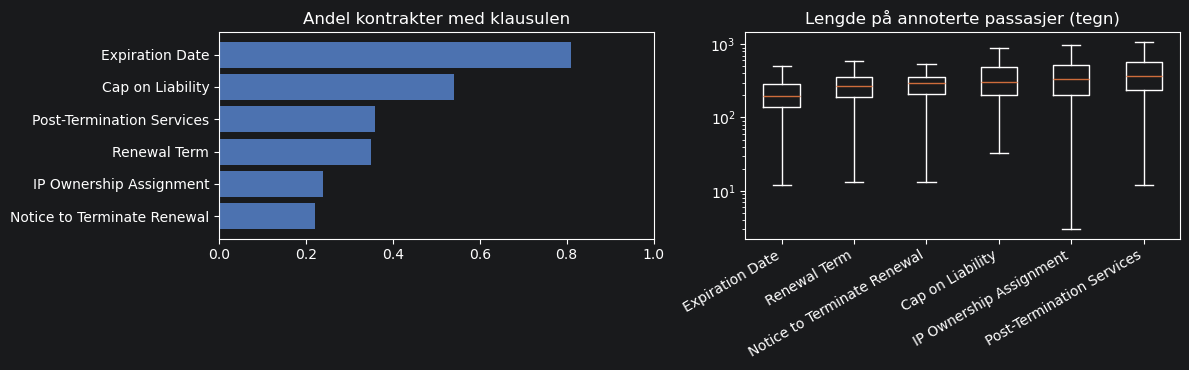

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
# Graf 1: andel kontrakter som har klausulen (viser klasseskjevhet)
o = oversikt.sort_values("andel med klausul")
ax[0].barh(o["kategori"], o["andel med klausul"], color="#4C72B0")
ax[0].set_xlim(0, 1); ax[0].set_title("Andel kontrakter med klausulen")
# Graf 2: lengde på annoterte passasjer (viktig for token-F1)
ax[1].boxplot([ann.loc[ann["kategori"] == c, "n_chars"] for c in CATS], showfliers=False)
ax[1].set_xticks(range(1, len(CATS) + 1)); ax[1].set_xticklabels([CATEGORIES[c] for c in CATS], rotation=30, ha="right")
ax[1].set_yscale("log"); ax[1].set_title("Lengde på annoterte passasjer (tegn)")
plt.tight_layout(); plt.show()

## 4. Oppdeling i utviklingssett og testsett

In [7]:

# Test = CUADs offisielle test-del. Den røres ikke før metodene er ferdig tilpasset.
# Dev  = tilfeldig utvalg fra train-delen. Her utvikler vi søkeregler og prompt.
# Reserve = resten av train (f.eks. til few-shot-eksempler).
# Delingen skjer per kontrakt, så tekst fra samme kontrakt aldri havner i både dev og test.
shuffled = sorted(train_titles)
random.Random(SEED).shuffle(shuffled)
dev_titles = set(shuffled[:DEV_SIZE])

for d in contracts:
    d["split"] = "test" if d["title"] in set(test_titles) else ("dev" if d["title"] in dev_titles else "reserve")

dev = [d for d in contracts if d["split"] == "dev"]
test = [d for d in contracts if d["split"] == "test"]
# Resten av treningsdelen brukes til å hente few-shot-eksempler.
reserve = sorted(
    [d for d in contracts if d["split"] == "reserve"],
    key=lambda d: d["title"],
)

# Kontroller at ingen kontrakter inngår i flere delmengder.
dev_ids = {d["title"] for d in dev}
test_ids = {d["title"] for d in test}
reserve_ids = {d["title"] for d in reserve}

assert dev_ids.isdisjoint(test_ids)
assert dev_ids.isdisjoint(reserve_ids)
assert test_ids.isdisjoint(reserve_ids)
print(len(dev), "dev |", len(test), "test |", len(contracts) - len(dev) - len(test), "reserve")

antall = pd.DataFrame({
    "dev": [sum(d["has"][c] for d in dev) for c in CATS],
    "test": [sum(d["has"][c] for d in test) for c in CATS],
}, index=[CATEGORIES[c] for c in CATS])
display(antall)    # antall kontrakter MED klausul i hver delmengde

100 dev | 102 test | 308 reserve


,dev,test
Expiration Date,82,78
Renewal Term,42,26
Notice to Terminate Renewal,27,16
Cap on Liability,59,44
IP Ownership Assignment,25,23
Post-Termination Services,44,29


## 5. Søkbasert referansemetode

In [8]:

# Idé: del kontrakten i avsnitt, gi hvert avsnitt poeng etter hvor mange nøkkeluttrykk som
# treffer, og returner de beste avsnittene hvis poengsummen er høy nok.
# Finnes ingen treff, svarer metoden "ingen klausul".
# Uttrykkene under er bare et STARTPUNKT: tilpass dem på dev-data (aldri på test).
PATTERNS = {
    "Expiration Date": [r"expire[sd]?", r"expiration", r"shall terminate on", r"initial term", r"continue in (full )?force"],
    "Renewal Term": [r"renew", r"automatically extend", r"successive (one|two|\d+)[- ]year", r"additional term"],
    "Notice Period To Terminate Renewal": [r"non-?renew", r"notice of (non-?renewal|termination)", r"prior written notice", r"not (to )?renew"],
    "Cap On Liability": [r"in no event shall .{0,80}liab", r"aggregate liability", r"shall not exceed", r"limitation of liability"],
    "Ip Ownership Assignment": [r"hereby assigns?", r"work made for hire", r"all right, title,? and interest", r"exclusive property"],
    "Post-Termination Services": [r"upon (termination|expiration)", r"following (termination|expiration)", r"transition services", r"wind[- ]down"],
}
COMPILED = {c: [re.compile(p, re.I) for p in ps] for c, ps in PATTERNS.items()}

def split_passages(text, min_len=40):
    # Del opp i avsnitt (tom linje mellom). Svært lange avsnitt deles videre på linjeskift.
    out = []
    for p in (x.strip() for x in re.split(r"\n\s*\n", text)):
        out.extend(p.split("\n") if len(p) > 3000 else [p])
    return [p.strip() for p in out if len(p.strip()) >= min_len]

MIN_SCORE, TOP_K = 1, 2     # VALG: terskel og maks antall utdrag. Tune på dev.

def keyword_predict(contract, cat):
    scored = []
    for p in split_passages(contract["text_llm"]):
        score = sum(1 for rx in COMPILED[cat] if rx.search(p))   # antall nøkkeluttrykk som treffer
        if score >= MIN_SCORE:
            scored.append((score, p))
    scored.sort(key=lambda x: -x[0])
    return [p for _, p in scored[:TOP_K]]       # tom liste = "fant ingen klausul"

## 6. LLM-basert metode

In [9]:
from getpass import getpass

client = None

if RUN_LLM:
    from openai import OpenAI

    # Skjult innskriving: nøkkelen skrives ikke inn i selve koden.
    api_key = getpass("Lim inn OpenAI API-nøkkelen din: ").strip()

    if not api_key:
        raise ValueError("Du må skrive inn en API-nøkkel.")

    try:
        client = OpenAI(api_key=api_key)
    finally:
        del api_key  # Fjern den midlertidige variabelen.

    # Her lagres modellens svar, ikke API-nøkkelen.
    CACHE_DIR.mkdir(exist_ok=True)

In [10]:

# Kontrakten deles i overlappende biter. Modellen får én bit og én klausultype om gangen og
# svarer med JSON: {"found": true/false, "passages": ["ordrett utdrag", ...]}.
# Utdragene fra alle bitene samles på kontraktsnivå. Alle kall caches på disk.
# Versjon 2: kategoribeskrivelser fra category_descriptions.csv.
PROMPT_VERSION = "v4_fewshot_selected"
VALIDATION_VERSION = "page_markers_v2"

DESCRIPTIONS = {
    "Expiration Date": (
    "Identify the passage specifying when the agreement's initial term "
    "expires or how long it lasts. This may be an explicit calendar date, "
    "a duration measured from the effective or commencement date, "
    "or a statement that the agreement continues indefinitely, perpetually, "
    "or until terminated by notice. "
    "A calendar date is not required: a stated initial-term duration "
    "is sufficient. Return the original passage, not a calculated date. "
    "Exclude durations that apply only to individual obligations, "
    "such as confidentiality or payment, rather than to the agreement itself."
),

    "Renewal Term": (
        "What is the renewal term after the initial term expires? "
        "This includes automatic extensions and unilateral extensions "
        "with prior notice."
    ),

    "Notice Period To Terminate Renewal": (
        "What is the notice period required to terminate renewal?"
    ),

    "Cap On Liability": (
        "Does the contract include a cap on liability upon the breach "
        "of a party’s obligation? This includes time limitation for "
        "the counterparty to bring claims or maximum amount for recovery."
    ),

    "Ip Ownership Assignment": (
        "Does intellectual property created by one party become the "
        "property of the counterparty, either per the terms of the "
        "contract or upon the occurrence of certain events?"
    ),

    "Post-Termination Services": (
        "Is a party subject to obligations after the termination or "
        "expiration of a contract, including any post-termination "
        "transition, payment, transfer of IP, wind-down, last-buy, "
        "or similar commitments?"
    ),
}

assert set(DESCRIPTIONS) == set(CATS)

SYSTEM_PROMPT = (
    "You are a careful contract-analysis assistant. You are given part of a commercial contract and a clause type. "
    "Decide whether this text contains a clause of that type. If so, return the relevant passages copied VERBATIM "
    "from the text (do not paraphrase; keep each passage as short as possible while covering the provision). "
    "If there is no such clause, say so. Respond ONLY with JSON: "
    '{"found": true/false, "passages": ["..."]}'
)

In [11]:
# Velg de samme reserveeksemplene som i few-shot-forsøket.
FEWSHOT_CATS = [
    "Ip Ownership Assignment",
    "Notice Period To Terminate Renewal",
    "Post-Termination Services",
]

fewshot_examples = {}

for cat in FEWSHOT_CATS:
    candidates = []

    for document in reserve:
        annotations = document["gold"][cat]

        if not annotations:
            continue

        # Alle fasitpassasjene for kategorien, med 500 tegn kontekst.
        start = max(
            0,
            min(g["start"] for g in annotations) - 500,
        )
        end = min(
            len(document["text"]),
            max(g["end"] for g in annotations) + 500,
        )

        if end - start > 5000:
            continue

        excerpt = document["text"][start:end]
        passages = list(dict.fromkeys(
            g["text"] for g in annotations
        ))

        assert all(p in excerpt for p in passages)

        candidates.append({
            "title": document["title"],
            "text": excerpt,
            "answer": {
                "found": True,
                "passages": passages,
            },
        })

    rng = random.Random(SEED)
    rng.shuffle(candidates)

    if len(candidates) < 2:
        raise ValueError(
            f"For få egnede reserveeksempler for {cat}."
        )

    fewshot_examples[cat] = candidates[:2]

example_titles = {
    example["title"]
    for examples in fewshot_examples.values()
    for example in examples
}

assert example_titles <= {d["title"] for d in reserve}

# Kort oversikt i stedet for å skrive ut alle eksempeltekstene.
display(pd.DataFrame([
    {
        "kategori": CATEGORIES[cat],
        "eksempel": i,
        "kontrakt": example["title"],
    }
    for cat, examples in fewshot_examples.items()
    for i, example in enumerate(examples, start=1)
]))

,kategori,eksempel,kontrakt
0,IP Ownership Assignment,1,MANUFACTURERSSERVICESLTD_06_05_2000-EX-10.14-O...
1,IP Ownership Assignment,2,JINGWEIINTERNATIONALLTD_10_04_2007-EX-10.7-INT...
2,Notice to Terminate Renewal,1,WaterNowInc_20191120_10-Q_EX-10.12_11900227_EX...
3,Notice to Terminate Renewal,2,SLOVAKWIRELESSFINANCECOBV_03_28_2001-EX-4.(B)(...
4,Post-Termination Services,1,NmfSlfIInc_20200115_10-12GA_EX-10.5_11946987_E...
5,Post-Termination Services,2,ELECTRAMECCANICA VEHICLES CORP. - Manufacturin...


In [12]:
def system_prompt_with_examples(cat):
    examples_text = []

    for i, example in enumerate(fewshot_examples[cat], start=1):
        examples_text.append(
            f"Example {i}\n"
            f"Contract text:\n<<<\n{example['text']}\n>>>\n"
            f"Expected JSON:\n"
            f"{json.dumps(example['answer'], ensure_ascii=False)}"
        )

    return (
        SYSTEM_PROMPT
        + "\n\nThe following annotated examples illustrate the clause "
          "type and the boundaries of the passages to extract. "
          "They are examples only, not part of the contract you must analyze. "
          "Extract passages only from the contract text in the user message. "
          "The examples are positive; the new text may contain no relevant "
          "clause, in which case return found=false and an empty passages list."
        + f"\n\nClause type: {cat}\n\n"
        + "\n\n".join(examples_text)
    )


FINAL_SYSTEM_PROMPTS = {
    cat: (
        system_prompt_with_examples(cat)
        if cat in FEWSHOT_CATS
        else SYSTEM_PROMPT
    )
    for cat in CATS
}

assert set(FINAL_SYSTEM_PROMPTS) == set(CATS)

In [13]:
def make_chunks(text, size=CHUNK_CHARS, overlap=OVERLAP_CHARS):
    # Korte kontrakter sendes hele. Lange deles i biter på 'size' tegn med 'overlap' tegn overlapp.
    if len(text) <= size:
        return [text]
    chunks, i = [], 0
    while True:
        chunks.append(text[i:i + size])
        if i + size >= len(text):
            return chunks
        i += size - overlap

#client = None
#if RUN_LLM:
#    from openai import OpenAI            # pip install openai
#    client = OpenAI()                    # leser OPENAI_API_KEY fra miljøet (aldri hardkod nøkkelen)
#   CACHE_DIR.mkdir(exist_ok=True)



def llm_call(chunk, cat):
    user = (
        f"Clause type: {cat}\n"
        f"Definition: {DESCRIPTIONS[cat]}\n\n"
        f"Contract text:\n<<<\n{chunk}\n>>>"
    )

    # Alle innstillinger som påvirker svaret, inngår i cache-nøkkelen.
    request = {
        "model": MODEL,
        "reasoning_effort": REASONING_EFFORT,
        "response_format": {"type": "json_object"},
        "messages": [
            {"role": "system", "content": FINAL_SYSTEM_PROMPTS[cat]},
            {"role": "user", "content": user},
        ],
    }

    key = hashlib.sha256(
        json.dumps(
            request, sort_keys=True, ensure_ascii=False
        ).encode("utf-8")
    ).hexdigest()

    CACHE_DIR.mkdir(exist_ok=True)
    cache_file = CACHE_DIR / f"{key}.json"

    # Gjenbruk svar når nøyaktig samme forespørsel er kjørt før.
    if cache_file.exists():
        with open(cache_file, encoding="utf-8") as f:
            return json.load(f)

    if client is None:
        raise RuntimeError(
            "Kjør cellen for API-nøkkelen med RUN_LLM = True først."
        )

    resp = client.chat.completions.create(**request)
    choice = resp.choices[0]

    # Tekniske problemer skal ikke registreres som «ingen klausul».
    if choice.finish_reason != "stop" or not choice.message.content:
        raise RuntimeError(
            f"Modellen ga ikke et fullstendig svar. "
            f"finish_reason={choice.finish_reason}"
        )

    raw = choice.message.content
    parsed = json.loads(raw)

    # Kontroller svarformatet før resultatet lagres.
    if (
        not isinstance(parsed, dict)
        or not isinstance(parsed.get("found"), bool)
        or not isinstance(parsed.get("passages"), list)
        or not all(isinstance(p, str) for p in parsed["passages"])
    ):
        raise ValueError("Modellsvaret har feil JSON-struktur.")

    out = {
        "model": resp.model,
        "reasoning_effort": REASONING_EFFORT,
        "raw": raw,
        "usage": resp.usage.model_dump() if resp.usage else None,
    }

    with open(cache_file, "w", encoding="utf-8") as f:
        json.dump(out, f, ensure_ascii=False, indent=2)

    return out

def passage_in_contract(passage, document):
    """Kontroller sitatet, med toleranse for utelatte sidemarkører."""

    if in_text(passage, document["text_llm"]):
        return True

    # Fjern bare sidemarkører som står alene på en linje:
    # «Page 23» eller «- 6 -».
    text_without_page_markers = re.sub(
        r"^[ \t]*(?:Page[ \t]+\d+|-[ \t]*\d+[ \t]*-)[ \t]*\r?$",
        "",
        document["text"],
        flags=re.MULTILINE,
    )

    return in_text(passage, text_without_page_markers)


def llm_predict(contract, cat):
    text = contract["text_llm"]
    funnet = []

    for ch in make_chunks(text):
        try:
            d = json.loads(llm_call(ch, cat)["raw"])
        except json.JSONDecodeError as exc:
            # Stopp ved ugyldig JSON, så feilen ikke blir et negativt treff.
            raise ValueError(
                f"Ugyldig JSON for {contract['title']} / {cat}"
            ) from exc

        if d.get("found"):
            funnet += [
                p for p in d.get("passages", [])
                if isinstance(p, str) and p.strip()
            ]

    # Fjern dubletter og kontroller at utdragene finnes i kontrakten.
    # Kontrollen tillater at sidemarkører på egne linjer er utelatt.
    seen, final = set(), []

    for p in funnet:
        if p not in seen and passage_in_contract(p, contract):
            seen.add(p)
            final.append(p)

    return final

## 7. Evalueringsmål

In [14]:
def tokens(s):
    return re.findall(r"\w+", s.lower())


def token_f1(a, b):
    ta, tb = tokens(a), tokens(b)

    if not ta or not tb:
        return 0.0

    common = sum((Counter(ta) & Counter(tb)).values())

    if common == 0:
        return 0.0

    precision = common / len(ta)
    recall = common / len(tb)

    return 2 * precision * recall / (precision + recall)


def collect_predictions(predict_fn, documents, categories):
    """Samle prediksjoner og fasit for samme dokumentutvalg."""
    details = []

    for cat in categories:
        print(f"Behandler: {CATEGORIES[cat]}", flush=True)

        for document in documents:
            details.append({
                "title": document["title"],
                "kategori": cat,
                "gold": [
                    g["text"] for g in document["gold"][cat]
                ],
                "pred": predict_fn(document, cat),
            })

    expected = {
        (d["title"], cat)
        for d in documents
        for cat in categories
    }

    assert len(details) == len(expected)
    assert {
        (r["title"], r["kategori"]) for r in details
    } == expected

    return details

In [15]:
EVAL_VERSION = "eval_v2"


def evaluate_saved(details, cats, name):
    """
    Evaluerer lagrede prediksjoner.

    Kontraktsnivå:
        Presisjon, recall og F1 for forekomst av klausultypen.

    Passasjenivå:
        Dekning av fasit: beste token-F1 for hver fasitpassasje.
        Treffsikkerhet for utdrag: beste token-F1 for hvert utdrag.

    Manglende treff gir null. Gjennomsnittene beregnes over
    henholdsvis alle fasitpassasjer og alle returnerte utdrag.
    """
    rows = []

    for cat in cats:
        category_details = [
            d for d in details if d["kategori"] == cat
        ]

        if not category_details:
            raise ValueError(f"Mangler resultater for {cat}.")

        titles = [d["title"] for d in category_details]
        if len(titles) != len(set(titles)):
            raise ValueError(f"Dupliserte kontraktresultater for {cat}.")

        tp = fp = fn = tn = 0
        gold_scores = []
        pred_scores = []

        for d in category_details:
            gold = d["gold"]
            pred = d["pred"]

            # Forekomst av klausultypen på kontraktsnivå.
            if gold and pred:
                tp += 1
            elif pred:
                fp += 1
            elif gold:
                fn += 1
            else:
                tn += 1

            # Hver fasitpassasje får en skår.
            # Ingen prediksjon betyr null.
            for g in gold:
                best_match = max(
                    (token_f1(p, g) for p in pred),
                    default=0.0,
                )
                gold_scores.append(best_match)

            # Hvert returnert utdrag får en skår.
            # Ingen fasit betyr null.
            for p in pred:
                best_match = max(
                    (token_f1(p, g) for g in gold),
                    default=0.0,
                )
                pred_scores.append(best_match)

        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0.0
        )

        rows.append({
            "metode": name,
            "kategori": CATEGORIES[cat],
            "antall_kontrakter": len(category_details),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn,
            "presisjon": precision,
            "recall": recall,
            "F1": f1,
            "antall_fasitpassasjer": len(gold_scores),
            "antall_utdrag": len(pred_scores),
            "dekning_fasit": (
                float(np.mean(gold_scores))
                if gold_scores else np.nan
            ),
            "treffsikkerhet_utdrag": (
                float(np.mean(pred_scores))
                if pred_scores else np.nan
            ),
        })

    return pd.DataFrame(rows)

## 8. Foreløpige resultater på utviklingssettet

In [16]:
assert 1 <= N_LLM_DEV <= len(dev)

eval_dev = list(dev[:N_LLM_DEV])
print("Utviklingskontrakter:", len(eval_dev))

det_kw = collect_predictions(
    keyword_predict, eval_dev, CATS
)

details_by_method = {"søk": det_kw}
det_llm = []

if RUN_LLM:
    det_llm = collect_predictions(
        llm_predict, eval_dev, CATS
    )
    details_by_method["LLM"] = det_llm

Utviklingskontrakter: 100
Behandler: Expiration Date
Behandler: Renewal Term
Behandler: Notice to Terminate Renewal
Behandler: Cap on Liability
Behandler: IP Ownership Assignment
Behandler: Post-Termination Services
Behandler: Expiration Date
Behandler: Renewal Term
Behandler: Notice to Terminate Renewal
Behandler: Cap on Liability
Behandler: IP Ownership Assignment
Behandler: Post-Termination Services


In [17]:
results_dev = pd.concat(
    [
        evaluate_saved(details, CATS, method)
        for method, details in details_by_method.items()
    ],
    ignore_index=True,
)

display(results_dev.round(3))

print("\nMakro-F1:")
print(results_dev.groupby("metode")["F1"].mean().round(3))

,metode,kategori,antall_kontrakter,TP,FP,FN,TN,presisjon,recall,F1,antall_fasitpassasjer,antall_utdrag,dekning_fasit,treffsikkerhet_utdrag
0,søk,Expiration Date,100,68,9,14,9,0.883,0.829,0.855,96,137,0.287,0.249
1,søk,Renewal Term,100,37,23,5,35,0.617,0.881,0.725,49,83,0.324,0.217
2,søk,Notice to Terminate Renewal,100,23,27,4,46,0.460,0.852,0.597,29,82,0.356,0.155
3,søk,Cap on Liability,100,43,5,16,36,0.896,0.729,0.804,129,66,0.228,0.331
4,søk,IP Ownership Assignment,100,21,18,4,57,0.538,0.840,0.656,63,53,0.269,0.227
5,søk,Post-Termination Services,100,32,21,12,35,0.604,0.727,0.660,95,82,0.269,0.240
6,LLM,Expiration Date,100,78,6,4,12,0.929,0.951,0.940,96,104,0.762,0.718
7,LLM,Renewal Term,100,41,10,1,48,0.804,0.976,0.882,49,56,0.783,0.680
8,LLM,Notice to Terminate Renewal,100,25,6,2,67,0.806,0.926,0.862,29,32,0.846,0.755
9,LLM,Cap on Liability,100,52,4,7,37,0.929,0.881,0.904,129,107,0.625,0.694



Makro-F1:
metode
LLM    0.840
søk    0.716
Name: F1, dtype: float64


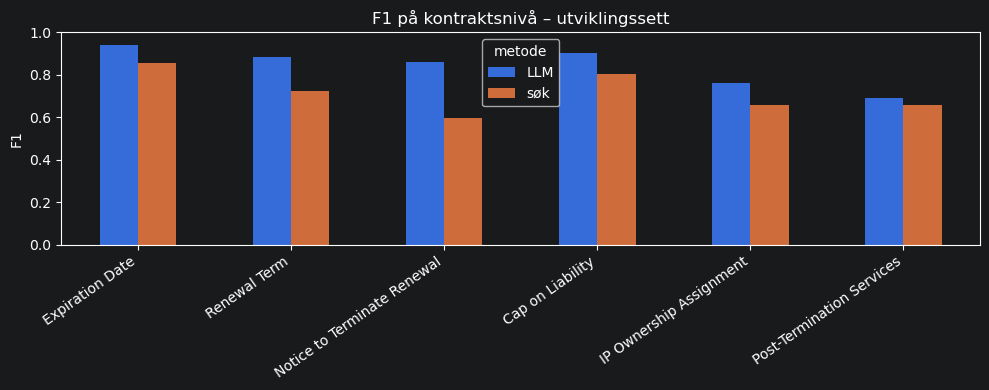

In [18]:
pivot_dev = results_dev.pivot(
    index="kategori",
    columns="metode",
    values="F1",
).reindex([CATEGORIES[c] for c in CATS])

ax = pivot_dev.plot.bar(figsize=(10, 4))
ax.set_title("F1 på kontraktsnivå – utviklingssett")
ax.set_xlabel("")
ax.set_ylabel("F1")
ax.set_ylim(0, 1)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 9. Feilanalyse

In [19]:

# Se på konkrete feil: falske negative (FN) og falske positive (FP). Noter eksempler til rapporten
# (feil klausul, utdrag som bare delvis dekker bestemmelsen, tilsynelatende oppdiktede utdrag osv.).
def vis_feil(details, type_="FN", n=3, bredde=300):
    vist = 0
    for d in details:
        fn_ = d["gold"] and not d["pred"]
        fp_ = d["pred"] and not d["gold"]
        if (type_ == "FN" and fn_) or (type_ == "FP" and fp_):
            print(f"--- {CATEGORIES[d['kategori']]} | {d['title'][:60]}")
            print("FASIT:", [norm_ws(g)[:bredde] for g in d["gold"][:2]])
            print("METODE:", [norm_ws(p)[:bredde] for p in d["pred"][:2]])
            vist += 1
            if vist >= n:
                break

print("=== Baseline: falske negative ==="); vis_feil(det_kw, "FN")
print("=== Baseline: falske positive ==="); vis_feil(det_kw, "FP")

=== Baseline: falske negative ===
--- Expiration Date | DOMINIADVISORTRUST_02_18_2005-EX-99.(H)(2)-SPONSORSHIP AGREE
FASIT: ['This Agreement shall become effective as of the day and year first above written and shall govern the relations between the parties hereto thereafter, unless terminated as set forth in this Section 6.']
METODE: []
--- Expiration Date | GLOBALTECHNOLOGIESLTD_06_08_2020-EX-10.16-CONSULTING AGREEME
FASIT: ['This Agreement shall be in full force and effect commencing on January 2, 2020 and shall remain in effect for one (1) year or until Consultant completes the services requested']
METODE: []
--- Expiration Date | AzulSa_20170303_F-1A_EX-10.3_9943903_EX-10.3_Maintenance Agr
FASIT: ['This Amendment shall enter into force on the date of its signature by both Parties and, unless otherwise agreed upon in writing by the Parties through a subsequent amendment to the GMA, shall remain in force for the term of the referenced GMA.']
METODE: []
=== Baseline: falske positive 

In [20]:
if RUN_LLM:
    for cat in [
        "Ip Ownership Assignment",
        "Post-Termination Services",
    ]:
        print(f"\n=== {CATEGORIES[cat]}: falske positive ===")

        category_details = [
            d for d in det_llm
            if d["kategori"] == cat
        ]

        vis_feil(
            category_details, "FP", n=3, bredde=1500
        )

    print("\n=== LLM: falske negative ===")
    vis_feil(det_llm, "FN", n=5, bredde=1500)

else:
    print("LLM-feilanalyse hoppes over: RUN_LLM=False.")


=== IP Ownership Assignment: falske positive ===
--- IP Ownership Assignment | SENMIAOTECHNOLOGYLTD_02_19_2019-EX-10.5-Collaboration Agreem
FASIT: []
METODE: ['Party A has exclusive rights and interests in all rights, ownership, titles, interests and intellectual property rights arising from or created by the performance of this Agreement.']
--- IP Ownership Assignment | ENTERTAINMENTGAMINGASIAINC_02_15_2005-EX-10.5-DISTRIBUTOR AG
FASIT: []
METODE: ['Any and all future inventions and improvements related to the Products licensed pursuant to this Agreement shall be the property of Vendor.']
--- IP Ownership Assignment | LinkPlusCorp_20050802_8-K_EX-10_3240252_EX-10_Affiliate Agre
FASIT: []
METODE: ['Axiometric and LKPL may develop other AMR Product Suites (e.g. for gas metering) and ownership of those AMR Product Suites will be held individually by the developer of the suite or jointly if mutually agreed to in writing.']

=== Post-Termination Services: falske positive ===
--- Post-Term

## 10. Lagring av resultater og oppsett

In [22]:
from datetime import datetime

# Egen mappe for hver kjøring. Tidligere resultater overskrives ikke.
RUN_DIR = OUT_DIR / (
    PROMPT_VERSION + "_" +
    datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
RUN_DIR.mkdir(parents=True, exist_ok=False)

results_dev.to_csv(
    RUN_DIR / "resultater_dev.csv",
    index=False,
)

with open(
    RUN_DIR / "prediksjoner_dev.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        details_by_method,
        f,
        ensure_ascii=False,
        indent=2,
    )

config = {
    "prompt_version": PROMPT_VERSION,
    "validation_version": VALIDATION_VERSION,
    "evaluation_version": EVAL_VERSION,
    "model": MODEL,
    "reasoning_effort": REASONING_EFFORT,
    "chunk_chars": CHUNK_CHARS,
    "overlap_chars": OVERLAP_CHARS,
    "seed": SEED,
    "dev_size": DEV_SIZE,
    "n_evaluated": len(eval_dev),
    "run_llm": RUN_LLM,
    "categories": CATEGORIES,
    "descriptions": DESCRIPTIONS,
    "base_system_prompt": SYSTEM_PROMPT,
    "system_prompts": FINAL_SYSTEM_PROMPTS,
    "fewshot_examples": fewshot_examples,
    "eval_titles": [d["title"] for d in eval_dev],
    "split_titles": {
        "dev": [d["title"] for d in dev],
        "reserve": [d["title"] for d in reserve],
        "test": [d["title"] for d in test],
    },
    "baseline": {
        "patterns": PATTERNS,
        "min_score": MIN_SCORE,
        "top_k": TOP_K,
    },
    "validation": {
        "page_marker_pattern":
            r"^[ \t]*(?:Page[ \t]+\d+|-[ \t]*\d+[ \t]*-)[ \t]*\r?$",
        "description":
            "Ordrett kontroll etter normalisering av whitespace. "
            "Sidemarkører på egne linjer kan være utelatt.",
    },
    "passage_metrics": {
        "dekning_fasit":
            "Gjennomsnittlig beste token-F1 per fasitpassasje.",
        "treffsikkerhet_utdrag":
            "Gjennomsnittlig beste token-F1 per returnert utdrag.",
        "missing_matches": "Gir null.",
        "matching":
            "Beste match innen samme kontrakt og kategori, "
            "uten krav om en-til-en-matching.",
    },
}

with open(
    RUN_DIR / "run_config.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("Lagret i:", RUN_DIR.resolve())

Lagret i: C:\Users\fredr\Documents\GitHub\llmProject\data\processed\v4_fewshot_selected_20261026_105216_943631


## 11. Endelig evaluering på testsettet

Vi evaluerer søkemetoden og LLM-metoden på CUADs offisielle testsett.
Prompter, few-shot-eksempler, søkeregler og øvrige innstillinger er
valgt på utviklingssettet og beholdes uendret under testevalueringen.

Begge metodene vurderes på de samme kontraktene. Testresultatene
brukes kun til sluttvurderingen, og ikke til videre tilpasning av metodene.

In [23]:
from copy import deepcopy
from datetime import datetime

if not RUN_LLM or client is None:
    raise RuntimeError(
        "Sett RUN_LLM = True og kjør API-nøkkelcellen i del 6."
    )

# Bruk hele det offisielle testsettet.
eval_test = list(test)

assert len(eval_test) > 0
assert len({d["title"] for d in eval_test}) == len(eval_test)

test_ids = {d["title"] for d in eval_test}
assert test_ids.isdisjoint({d["title"] for d in dev})
assert test_ids.isdisjoint({d["title"] for d in reserve})

# Kontroller at promptene ikke er endret etter lagring i del 10.
assert config["system_prompts"] == FINAL_SYSTEM_PROMPTS
assert config["descriptions"] == DESCRIPTIONS
assert config["model"] == MODEL
assert config["reasoning_effort"] == REASONING_EFFORT
assert config["chunk_chars"] == CHUNK_CHARS
assert config["overlap_chars"] == OVERLAP_CHARS
assert config["baseline"] == {
    "patterns": PATTERNS,
    "min_score": MIN_SCORE,
    "top_k": TOP_K,
}

TEST_DIR = OUT_DIR / (
    PROMPT_VERSION + "_test_" +
    datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
TEST_DIR.mkdir(parents=True, exist_ok=False)

# Dokumenter oppsettet før testkjøringen.
test_config = deepcopy(config)
test_config.update({
    "evaluation_split": "test",
    "n_evaluated": len(eval_test),
    "eval_titles": [d["title"] for d in eval_test],
})

with open(TEST_DIR / "run_config.json", "w", encoding="utf-8") as f:
    json.dump(test_config, f, ensure_ascii=False, indent=2)

print("Antall testkontrakter:", len(eval_test))

print("\n=== Søk ===")
det_kw_test = collect_predictions(
    keyword_predict, eval_test, CATS
)

print("\n=== LLM ===")
det_llm_test = collect_predictions(
    llm_predict, eval_test, CATS
)

test_details_by_method = {
    "søk": det_kw_test,
    "LLM": det_llm_test,
}

with open(
    TEST_DIR / "prediksjoner_test.json", "w", encoding="utf-8"
) as f:
    json.dump(
        test_details_by_method, f,
        ensure_ascii=False, indent=2,
    )

print("\nTestprediksjoner lagret i:", TEST_DIR.resolve())

Antall testkontrakter: 102

=== Søk ===
Behandler: Expiration Date
Behandler: Renewal Term
Behandler: Notice to Terminate Renewal
Behandler: Cap on Liability
Behandler: IP Ownership Assignment
Behandler: Post-Termination Services

=== LLM ===
Behandler: Expiration Date
Behandler: Renewal Term
Behandler: Notice to Terminate Renewal
Behandler: Cap on Liability
Behandler: IP Ownership Assignment
Behandler: Post-Termination Services

Testprediksjoner lagret i: C:\Users\fredr\Documents\GitHub\llmProject\data\processed\v4_fewshot_selected_test_20261026_105339_621689


In [24]:
results_test = pd.concat(
    [
        evaluate_saved(details, CATS, method)
        for method, details in test_details_by_method.items()
    ],
    ignore_index=True,
)

display(results_test.round(3))

macro_test = results_test.groupby("metode")["F1"].mean()

print("\n=== Endelig resultat på testsettet ===")
print(f"Antall kontrakter per metode: {len(eval_test)}")
print(f"Søk – makro-F1: {macro_test['søk']:.3f}")
print(f"LLM – makro-F1: {macro_test['LLM']:.3f}")
print(
    f"Forskjell (LLM − søk): "
    f"{macro_test['LLM'] - macro_test['søk']:+.3f}"
)

results_test.to_csv(
    TEST_DIR / "resultater_test.csv", index=False
)

,metode,kategori,antall_kontrakter,TP,FP,FN,TN,presisjon,recall,F1,antall_fasitpassasjer,antall_utdrag,dekning_fasit,treffsikkerhet_utdrag
0,søk,Expiration Date,102,65,5,13,19,0.929,0.833,0.878,83,121,0.248,0.217
1,søk,Renewal Term,102,23,25,3,51,0.479,0.885,0.622,31,69,0.392,0.188
2,søk,Notice to Terminate Renewal,102,14,27,2,59,0.341,0.875,0.491,18,61,0.385,0.123
3,søk,Cap on Liability,102,22,9,22,49,0.710,0.500,0.587,118,40,0.159,0.300
4,søk,IP Ownership Assignment,102,19,15,4,64,0.559,0.826,0.667,61,51,0.283,0.228
5,søk,Post-Termination Services,102,19,14,10,59,0.576,0.655,0.613,82,50,0.192,0.190
6,LLM,Expiration Date,102,74,6,4,18,0.925,0.949,0.937,83,93,0.846,0.769
7,LLM,Renewal Term,102,25,11,1,65,0.694,0.962,0.806,31,46,0.767,0.533
8,LLM,Notice to Terminate Renewal,102,15,2,1,84,0.882,0.938,0.909,18,17,0.799,0.814
9,LLM,Cap on Liability,102,44,12,0,46,0.786,1.000,0.880,118,106,0.643,0.647



=== Endelig resultat på testsettet ===
Antall kontrakter per metode: 102
Søk – makro-F1: 0.643
LLM – makro-F1: 0.784
Forskjell (LLM − søk): +0.141


Makro-F1 på kontraktsnivå:


,Utviklingssett,Testsett
metode,,
LLM,0.840,0.784
søk,0.716,0.643


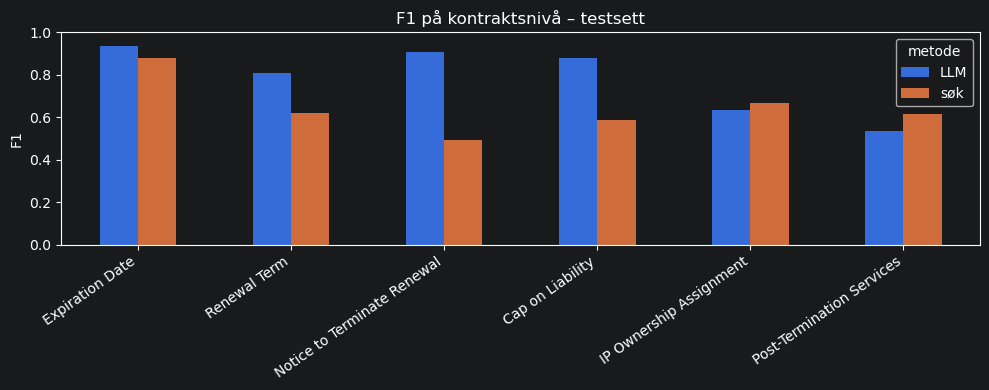

In [25]:
comparison = pd.DataFrame({
    "Utviklingssett": (
        results_dev.groupby("metode")["F1"].mean()
    ),
    "Testsett": macro_test,
})

print("Makro-F1 på kontraktsnivå:")
display(comparison.round(3))

pivot_test = results_test.pivot(
    index="kategori",
    columns="metode",
    values="F1",
).reindex([CATEGORIES[c] for c in CATS])

ax = pivot_test.plot.bar(figsize=(10, 4))
ax.set_title("F1 på kontraktsnivå – testsett")
ax.set_xlabel("")
ax.set_ylabel("F1")
ax.set_ylim(0, 1)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(TEST_DIR / "f1_test.png", dpi=200)
plt.show()

comparison.to_csv(TEST_DIR / "makro_f1_dev_test.csv")

## 12. Supplerende evaluering og usikkerhet

Makro-F1 beholdes som hovedmål fordi hver klausultype skal telle like mye.
Viser allikevel også mikro-F1, som beregnes fra samlet TP, FP og FN, og
vektet F1, der kategoriene vektes etter antall kontrakter med annotert klausul.

For å undersøke usikkerheten i forskjellen mellom metodene bruker vi
parret bootstrap med 5000 trekninger. Hele kontrakter trekkes med
tilbakelegging. Alle seks kategorier og begge metoders prediksjoner
følger kontrakten i hver trekning.

Dette er supplerende analyser etter testkjøringen, så metodene og prediksjonene endres ikke.

In [26]:
import numpy as np
import pandas as pd

# Én rad per kontrakt og én kolonne per klausultype.
test_titles_eval = sorted(d["title"] for d in eval_test)
expected_pairs = {
    (title, cat)
    for title in test_titles_eval
    for cat in CATS
}


def prediction_matrices(details):
    lookup = {
        (r["title"], r["kategori"]): r
        for r in details
    }

    if len(lookup) != len(details):
        raise ValueError("Dupliserte kontrakt/kategori-par.")

    if set(lookup) != expected_pairs:
        raise ValueError("Mangler eller har ekstra testprediksjoner.")

    gold = np.array([
        [bool(lookup[(title, cat)]["gold"]) for cat in CATS]
        for title in test_titles_eval
    ], dtype=bool)

    pred = np.array([
        [bool(lookup[(title, cat)]["pred"]) for cat in CATS]
        for title in test_titles_eval
    ], dtype=bool)

    return gold, pred


y_test_gold, y_test_kw = prediction_matrices(
    test_details_by_method["søk"]
)
gold_llm, y_test_llm = prediction_matrices(
    test_details_by_method["LLM"]
)

assert np.array_equal(y_test_gold, gold_llm)


def presence_f1_scores(gold, pred):
    """F1 for klausulforekomst, ikke for tekstoverlapp."""
    tp = (gold & pred).sum(axis=0)
    fp = (~gold & pred).sum(axis=0)
    fn = (gold & ~pred).sum(axis=0)

    denominator = 2 * tp + fp + fn

    # F1 settes til 0 dersom nevneren er 0.
    f1_per_category = np.divide(
        2 * tp,
        denominator,
        out=np.zeros(len(tp), dtype=float),
        where=denominator != 0,
    )

    support = gold.sum(axis=0)
    total_denominator = denominator.sum()

    return {
        "Makro-F1": float(f1_per_category.mean()),
        "Mikro-F1": (
            float(2 * tp.sum() / total_denominator)
            if total_denominator else 0.0
        ),
        "Vektet F1": (
            float(np.average(f1_per_category, weights=support))
            if support.sum() else 0.0
        ),
    }


supplementary_f1 = pd.DataFrame([
    {"Metode": method, **presence_f1_scores(y_test_gold, pred)}
    for method, pred in [
        ("søk", y_test_kw),
        ("LLM", y_test_llm),
    ]
]).set_index("Metode")

# Kontroller at makro-F1 samsvarer med den eksisterende evalueringen.
for method in supplementary_f1.index:
    existing_macro = results_test.loc[
        results_test["metode"] == method, "F1"
    ].mean()

    assert np.isclose(
        supplementary_f1.loc[method, "Makro-F1"],
        existing_macro,
    )

display(supplementary_f1.round(3))

supplementary_f1.to_csv(
    TEST_DIR / "supplerende_f1_test.csv"
)

,Makro-F1,Mikro-F1,Vektet F1
Metode,,,
søk,0.643,0.685,0.701
LLM,0.784,0.789,0.822


In [27]:
N_BOOTSTRAP = 5000
BOOTSTRAP_SEED = 42

rng = np.random.default_rng(BOOTSTRAP_SEED)
n_contracts = len(y_test_gold)

bootstrap_values = np.empty((N_BOOTSTRAP, 3))

for b in range(N_BOOTSTRAP):
    # Trekk hele kontrakter, med alle kategoriene samlet.
    indices = rng.integers(
        0, n_contracts, size=n_contracts
    )

    sampled_gold = y_test_gold[indices]

    score_kw = presence_f1_scores(
        sampled_gold, y_test_kw[indices]
    )["Makro-F1"]

    score_llm = presence_f1_scores(
        sampled_gold, y_test_llm[indices]
    )["Makro-F1"]

    bootstrap_values[b] = [
        score_kw,
        score_llm,
        score_llm - score_kw,
    ]

observed_kw = supplementary_f1.loc["søk", "Makro-F1"]
observed_llm = supplementary_f1.loc["LLM", "Makro-F1"]

lower, upper = np.quantile(
    bootstrap_values, [0.025, 0.975], axis=0
)

bootstrap_summary = pd.DataFrame({
    "Mål": [
        "Søk – makro-F1",
        "LLM – makro-F1",
        "Forskjell: LLM − søk",
    ],
    "Observert": [
        observed_kw,
        observed_llm,
        observed_llm - observed_kw,
    ],
    "95 % KI nedre": lower,
    "95 % KI øvre": upper,
})

display(bootstrap_summary.round(3))

print(
    f"\nForskjell i makro-F1: "
    f"{observed_llm - observed_kw:.3f}"
)
print(
    f"95 % bootstrap-konfidensintervall: "
    f"[{lower[2]:.3f}, {upper[2]:.3f}]"
)

if lower[2] > 0:
    print(
        "Hele intervallet er over null. Analysen støtter "
        "at LLM har høyere makro-F1 enn søk."
    )
elif upper[2] < 0:
    print(
        "Hele intervallet er under null. Analysen støtter "
        "at søk har høyere makro-F1 enn LLM."
    )
else:
    print(
        "Intervallet omfatter null. Analysen gir ikke "
        "klar støtte til en forskjell i makro-F1."
    )

bootstrap_summary.to_csv(
    TEST_DIR / "bootstrap_makro_f1_test.csv",
    index=False,
)

pd.DataFrame(
    bootstrap_values,
    columns=["søk", "LLM", "forskjell"],
).to_csv(
    TEST_DIR / "bootstrap_trekninger.csv",
    index=False,
)

with open(
    TEST_DIR / "bootstrap_oppsett.json", "w", encoding="utf-8"
) as f:
    json.dump({
        "n_bootstrap": N_BOOTSTRAP,
        "seed": BOOTSTRAP_SEED,
        "n_contracts": n_contracts,
        "categories": CATS,
        "sampling_unit": "Hel kontrakt med alle kategorier",
        "paired": True,
        "interval_method": "Percentilintervall: 2.5 og 97.5",
        "zero_division": 0,
    }, f, ensure_ascii=False, indent=2)

,Mål,Observert,95 % KI nedre,95 % KI øvre
0,Søk – makro-F1,0.643,0.574,0.700
1,LLM – makro-F1,0.784,0.728,0.830
2,Forskjell: LLM − søk,0.141,0.086,0.203



Forskjell i makro-F1: 0.141
95 % bootstrap-konfidensintervall: [0.086, 0.203]
Hele intervallet er over null. Analysen støtter at LLM har høyere makro-F1 enn søk.
